# Aspect extraction and end-to-end evaluation

Fine-tunes a BERT token classifier that finds aspect terms in a review, scores it on the official test file by exact and overlap span match, and then classifies the extracted terms with the BERT sentiment model from notebook 03 to give an end-to-end figure. Extraction and sentiment are reported separately, and the errors are broken into boundary, missed and spurious spans.

## Setup

Run this on a Colab GPU runtime (*Runtime → Change runtime type → GPU*). The cell clones the repository, installs the dependencies and checks the environment. Colab keeps its own `torch`, so it is left as it is.

In [1]:
import os

if not os.path.isdir("aspect-based-sentiment-analysis"):
    !git clone -q https://github.com/Shivam-Shukla0/aspect-based-sentiment-analysis.git
%cd aspect-based-sentiment-analysis
!pip install -q -r requirements.txt
!pip install -q -e . --no-deps
!python -m scripts.verify_environment --require-gpu

/content/run/aspect-based-sentiment-analysis


  Installing build dependencies ... done


  Checking if build backend supports build_editable ... done


  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done


  Building editable for absa (pyproject.toml) ... done


python          3.13.16
numpy           2.4.6
pandas          2.2.3
scikit-learn    1.6.1
lxml            6.1.3
torch           2.14.1+cu130
transformers    5.22.1
accelerate      1.15.0
sentencepiece   0.2.2
matplotlib      3.10.0
flask           3.1.3
absa            0.1.0
device          NVIDIA L4 (CUDA 13.0, 1 device)
environment ok


## Data

The official SemEval-2014 Task 4 files are distributed through the ILSP Metashare repository and need an account and acceptance of its licence (see `data/README.md`). This cell uses those files when they are in Google Drive (set `USE_DRIVE = True` after mounting Drive), and otherwise downloads the same four files from a public Hugging Face mirror of the dataset. The mirror did not come through the official route, so the file checksums are printed and the report states this limitation. Nothing in `data/` is committed to Git.

In [2]:
from pathlib import Path

USE_DRIVE = False  # True: copy the official files from DRIVE_DIR (mount Drive first)
DRIVE_DIR = Path("/content/drive/MyDrive/absa/semeval2014")
MIRROR = "https://huggingface.co/datasets/alexcadillon/SemEval2014Task4/resolve/main"
TRAIN = "SemEval%2714-ABSA-TrainData_v2%20%26%20AnnotationGuidelines"
FILES = {
    "Laptop_Train_v2.xml": (f"{MIRROR}/{TRAIN}/Laptop_Train_v2.xml", "laptop", "train"),
    "Restaurants_Train_v2.xml": (f"{MIRROR}/{TRAIN}/Restaurants_Train_v2.xml", "restaurant", "train"),
    "Laptops_Test_Gold.xml": (f"{MIRROR}/ABSA_Gold_TestData/Laptops_Test_Gold.xml", "laptop", "test"),
    "Restaurants_Test_Gold.xml": (
        f"{MIRROR}/ABSA_Gold_TestData/Restaurants_Test_Gold.xml",
        "restaurant",
        "test",
    ),
}
Path("data/raw").mkdir(parents=True, exist_ok=True)
for name, (url, domain, split) in FILES.items():
    if USE_DRIVE:
        !cp "{DRIVE_DIR / name}" data/raw/
    else:
        !curl -sL -o data/raw/{name} "{url}"
    !python -m scripts.build_processed data/raw/{name} --domain {domain} --split {split} > /dev/null
!sha256sum data/raw/*.xml
!wc -l data/processed/*.jsonl

aa3a30c9dd7e0eacf9b69e898eb4118a36c1b4f391a30a08dfc41a38d8b8745b  data/raw/Laptops_Test_Gold.xml
efec2ed73b4efb83b47c697114d800149c558118884afa80362a6e975ba7248c  data/raw/Laptop_Train_v2.xml
f21509cfa37e16534cd5b2da043be487355b64ef48fe8d6aaacaeca6b49cc0fb  data/raw/Restaurants_Test_Gold.xml
223601da1bded6caa4ef9cf91a7007578141ca6d8ed50d5a5c217565f89d2fc5  data/raw/Restaurants_Train_v2.xml


    654 data/processed/laptop_test.jsonl
    378 data/processed/laptop_test_no_aspect.jsonl
   2358 data/processed/laptop_train.jsonl
   1557 data/processed/laptop_train_no_aspect.jsonl
   1134 data/processed/restaurant_test.jsonl
    194 data/processed/restaurant_test_no_aspect.jsonl
   3693 data/processed/restaurant_train.jsonl
   1020 data/processed/restaurant_train_no_aspect.jsonl
  10988 total


## Train and evaluate

The learning rate is chosen on a validation split of the training sentences (exact-match span F1); the test file is read once. If notebook 03 has been run in the same session, its best sentiment model is used for the end-to-end score.

In [3]:
import json
from pathlib import Path


def best_classifier(domain):
    summary = Path(f"outputs/bert_{domain}/summary.json")
    if not summary.exists():
        return None
    runs = json.load(open(summary))["runs"]
    best = max(range(len(runs)), key=lambda i: runs[i]["val_macro_f1"])
    return f"outputs/bert_{domain}/run_{best}/model"


for domain in ("laptop", "restaurant"):
    classifier = best_classifier(domain)
    flag = f"--classifier-dir {classifier}" if classifier else ""
    print(domain, "- sentiment model for the end-to-end score:", classifier)
    !python -m scripts.train_extractor --domain {domain} {flag} | grep -E "^(run|{domain})"

laptop - sentiment model for the end-to-end score: outputs/bert_laptop/run_2/model


Loading weights: 100% 197/197 [00:00<00:00, 4144.84it/s]
[transformers] BertForTokenClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you 

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:910.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Writing model shards:   0% 0/1 [00:00<?, ?it/s]

Writing model shards: 100% 1/1 [00:00<00:00,  3.03it/s]


run 0: lr 3e-05 val span F1 0.8106
Loading weights: 100% 197/197 [00:00<00:00, 3823.20it/s]
[transformers] BertForTokenClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from differen

... (11 outputs left out)

Writing model shards:   0% 0/1 [00:00<?, ?it/s]

Writing model shards: 100% 1/1 [00:00<00:00,  3.03it/s]
run 1: lr 5e-05 val span F1 0.8606
Loading weights: 100% 199/199 [00:00<00:00, 4906.77it/s]


Loading weights: 100% 201/201 [00:00<00:00, 5261.10it/s]


restaurant: test exact span F1 0.8775


## Results

In [4]:
import pandas as pd

rows = []
for domain in ("laptop", "restaurant"):
    summary = json.load(open(f"outputs/extractor_{domain}/summary.json"))
    for name, key in (("extraction, exact match", "test_exact"), ("extraction, overlap match", "test_overlap"), ("end to end", "end_to_end")):
        if key in summary:
            rows.append({"domain": domain, "setting": name, **{k: round(summary[key][k], 3) for k in ("precision", "recall", "f1")}})
    print(domain, "- validation F1 per learning rate:", [(r["learning_rate"], round(r["val_f1"], 3)) for r in summary["runs"]],
          "| training sentences skipped (untaggable gold spans):", summary["skipped_training_sentences"])
pd.DataFrame(rows)

laptop - validation F1 per learning rate: [(3e-05, 0.811), (5e-05, 0.821)] | training sentences skipped (untaggable gold spans): 0
restaurant - validation F1 per learning rate: [(3e-05, 0.854), (5e-05, 0.861)] | training sentences skipped (untaggable gold spans): 0


,domain,setting,precision,recall,f1
0,laptop,"extraction, exact match",0.806,0.757,0.781
1,laptop,"extraction, overlap match",0.920,0.864,0.891
2,laptop,end to end,0.603,0.580,0.591
3,restaurant,"extraction, exact match",0.865,0.891,0.877
4,restaurant,"extraction, overlap match",0.927,0.955,0.941
5,restaurant,end to end,0.711,0.742,0.726


## Error breakdown

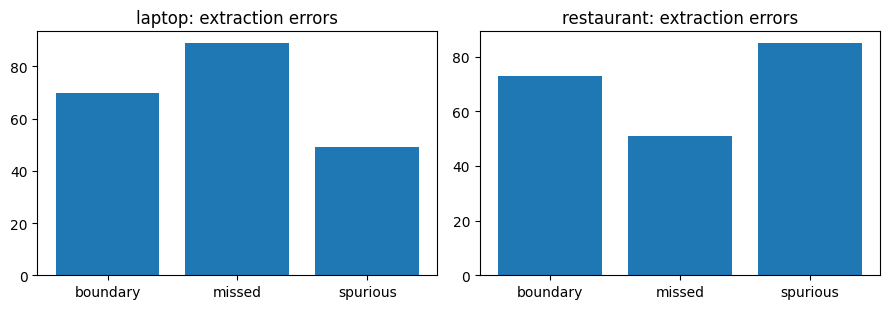

laptop
  boundary  gold='price tag'                  predicted='price'                      | Other than not being a fan of click pads (industry standard these days
  boundary  gold='installation disk (DVD)'    predicted='installation disk'          | No installation disk (DVD) is included.
  boundary  gold='apple OS'                   predicted='OS'                         | Works well, and I am extremely happy to be back to an apple OS.
  spurious  gold=''                           predicted='engineers'                  | The Apple engineers have not yet discovered the delete key.
  missed    gold='works'                      predicted=''                           | Super light, super sexy and everything just works.
  missed    gold='mountain lion'              predicted=''                           | But the mountain lion is just too slow.
  spurious  gold=''                           predicted='charging'                   | The battery life is excellent- 6-7 hours without charging.

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, domain in zip(axes, ("laptop", "restaurant")):
    report = json.load(open(f"outputs/extractor_{domain}/test_report.json"))
    counts = report["error_counts"]
    ax.bar(list(counts), list(counts.values()))
    ax.set_title(f"{domain}: extraction errors")
plt.tight_layout()
plt.show()

for domain in ("laptop", "restaurant"):
    report = json.load(open(f"outputs/extractor_{domain}/test_report.json"))
    print(domain)
    for error in report["error_examples"][:8]:
        print(f"  {error['kind']:9s} gold={error['gold']!r:28} predicted={error['predicted']!r:28} | {error['text'][:70]}")